# Case iFood · Parte 3: modelo de propensão e maximização do lucro

**Autor:** Victor Maurício · **Notebook 3 de 3** ·
[← Parte 1: análise exploratória](01_eda_e_tratamento.ipynb) ·
[← Parte 2: segmentação](02_segmentacao_clientes.ipynb)

## 1. Objetivo

O terceiro entregável do case é **um modelo de classificação que permita à empresa maximizar o lucro da próxima
campanha**. O modelo estima, para cada cliente, a probabilidade de aceitar a oferta, e a empresa contata só os
clientes com probabilidade alta o suficiente.

A conta da campanha é simples:

$$\text{lucro} = 11 \times \text{aceites} - 3 \times \text{contatos}$$

Um contato só se paga se a chance de aceite for maior que **3/11 ≈ 27,3%**, o ponto de equilíbrio entre custo
e receita esperada. Esse número guia a escolha do limiar de decisão na seção 7.

O case também orienta: *"simplicidade e consciência do que está acontecendo é preferível a implementações de
algoritmos complexos que você não domina"*. Por isso damos preferência a modelos interpretáveis.

In [1]:
from platform import python_version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from imblearn import __version__ as versao_imblearn
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from src.auxiliares import dataframe_coeficientes
from src.config import (
    CUSTO_CONTATO,
    DADOS_CLUSTERIZADOS,
    DADOS_TRATADOS,
    MODELO_FINAL,
    RANDOM_STATE,
    RECEITA_ACEITE,
)
from src.graficos import (
    plot_coeficientes,
    plot_comparar_metricas_modelos,
    plot_curva_de_lucro,
    salvar_figura,
)
from src.modelos import (
    curva_de_lucro,
    grid_search_classificador,
    lucro_campanha,
    organizar_resultados,
    treinar_e_validar_classificador,
)

sns.set_theme(style="whitegrid", palette="tab10")

LIMIAR_EQUILIBRIO = CUSTO_CONTATO / RECEITA_ACEITE

print(f"Python {python_version()} | scikit-learn {sklearn.__version__} | imbalanced-learn {versao_imblearn}")
print(f"Ponto de equilíbrio: {LIMIAR_EQUILIBRIO:.1%}")

Python 3.13.5 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2
Ponto de equilíbrio: 27.3%


## 2. Dados e separação entre treino e teste

Usamos a base tratada da [Parte 1](01_eda_e_tratamento.ipynb). **O rótulo de cluster da Parte 2 não entra como
variável:** o K-Means foi ajustado em toda a base, e usá-lo levaria informação do conjunto de teste para o treino.

Separamos **20% dos clientes como conjunto de teste**, estratificado para manter a proporção de aceites.
Todas as escolhas (modelo, hiperparâmetros e limiar) são feitas só com o treino, por validação cruzada.
O teste é usado uma única vez, na seção 8, para estimar o desempenho em clientes novos.

In [2]:
df = pd.read_parquet(DADOS_TRATADOS)

X = df.drop(columns="Response")
y = df["Response"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

pd.DataFrame(
    {
        "clientes": [len(y_treino), len(y_teste)],
        "aceites": [y_treino.sum(), y_teste.sum()],
        "taxa_aceite": [y_treino.mean(), y_teste.mean()],
    },
    index=["treino", "teste"],
).style.format({"taxa_aceite": "{:.1%}"})

,clientes,aceites,taxa_aceite
treino,1618,250,15.5%
teste,405,62,15.3%


## 3. Pré-processamento

As transformações seguem a lógica da [segmentação](02_segmentacao_clientes.ipynb) (seção 3),
com duas diferenças no `OneHotEncoder`:

- `drop="if_binary"`: colunas binárias (como `AcceptedCmp5`) viram uma única coluna, e não duas. Isso evita
  coeficientes redundantes e facilita a interpretação do modelo;
- `handle_unknown="ignore"`: uma categoria nova em dados futuros não quebra o modelo.

In [3]:
colunas_one_hot = [
    "Education",
    "Marital_Status",
    "AgeGroup",
    "Kidhome",
    "Teenhome",
    "Children",
    "HasChildren",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "AcceptedCmpTotal",
    "HasAcceptedCmp",
    "Complain",
    "YearsSinceEnrolled",
]
colunas_standard = ["Income", "Age"]
colunas_power = X.columns[X.columns.str.startswith(("Mnt", "Num"))].tolist()
colunas_minmax = [
    coluna for coluna in X.columns
    if coluna not in colunas_one_hot + colunas_standard + colunas_power
]

preprocessador = ColumnTransformer(
    [
        ("one_hot", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), colunas_one_hot),
        ("standard", StandardScaler(), colunas_standard),
        ("minmax", MinMaxScaler(), colunas_minmax),
        ("power", PowerTransformer(), colunas_power),
    ]
)

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 4. Comparação de modelos

Comparamos quatro modelos simples, todos com as configurações padrão:

- **`DummyClassifier`** (estratégia `stratified`): ignora as variáveis e "chuta" a classe respeitando a proporção
  de aceites. É a **linha de base**: um modelo só tem valor se for claramente melhor que ele.
- **Regressão logística:** modelo linear que transforma uma soma ponderada das variáveis em probabilidade.
  Os coeficientes mostram o peso de cada variável, o que a torna fácil de explicar.
- **Árvore de decisão:** uma sequência de regras do tipo "se... então...". Captura relações não lineares,
  mas tende a se ajustar demais aos dados de treino (*overfitting*) se não for limitada.
- **k vizinhos mais próximos (kNN):** classifica um cliente pela maioria dos *k* clientes mais parecidos.
  Depende de distâncias, por isso também precisa do pré-processamento.

O pipeline (em [`src/modelos.py`](src/modelos.py)) tem pré-processamento, seleção de variáveis (`SelectKBest`,
aqui com todas as variáveis) e **undersampling** (`RandomUnderSampler`), que descarta aleatoriamente clientes da
classe majoritária no treino até as classes ficarem do mesmo tamanho. O pipeline do imbalanced-learn garante que
o undersampling é aplicado **só nos dados de treino de cada fold**, nunca nos de validação.

**Métricas.** Com 15% de aceites, a acurácia engana: um modelo que responde "não aceita" para todos acerta 85%.
Olhamos principalmente:

- **AUPRC (*average precision*):** resume o equilíbrio entre precisão (dos contatados, quantos aceitam) e
  recall (dos que aceitariam, quantos contatamos). O valor de referência é a taxa de aceites (0,15);
- **ROC-AUC:** probabilidade de o modelo dar nota maior a um cliente que aceita do que a um que não aceita.
  0,5 é o acaso e 1 é a separação perfeita.

A validação cruzada estratificada divide o treino em 5 partes (*folds*) e treina 5 vezes, cada vez validando em
uma parte diferente. Por isso cada modelo tem **5 valores por métrica**, e os boxplots mostram a variação entre eles.

In [4]:
classificadores = {
    "DummyClassifier": {
        "preprocessador": None,
        "classificador": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    },
    "LogisticRegression": {
        "preprocessador": preprocessador,
        "classificador": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    },
    "DecisionTreeClassifier": {
        "preprocessador": preprocessador,
        "classificador": DecisionTreeClassifier(random_state=RANDOM_STATE),
    },
    "KNeighborsClassifier": {
        "preprocessador": preprocessador,
        "classificador": KNeighborsClassifier(),
    },
}

resultados = {
    nome: treinar_e_validar_classificador(X_treino, y_treino, kf, **parametros)
    for nome, parametros in classificadores.items()
}

df_resultados = organizar_resultados(resultados)

(
    df_resultados.groupby("model")
    .mean()
    .sort_values("test_average_precision", ascending=False)
    [["test_average_precision", "test_roc_auc", "test_precision", "test_recall", "test_f1", "test_balanced_accuracy", "time_seconds"]]
    .round(3)
)

,test_average_precision,test_roc_auc,test_precision,test_recall,test_f1,test_balanced_accuracy,time_seconds
model,,,,,,,
LogisticRegression,0.671,0.904,0.459,0.832,0.591,0.826,0.168
KNeighborsClassifier,0.355,0.770,0.332,0.640,0.436,0.702,0.522
DecisionTreeClassifier,0.274,0.725,0.313,0.748,0.441,0.724,0.338
DummyClassifier,0.168,0.542,0.177,0.548,0.268,0.542,0.028


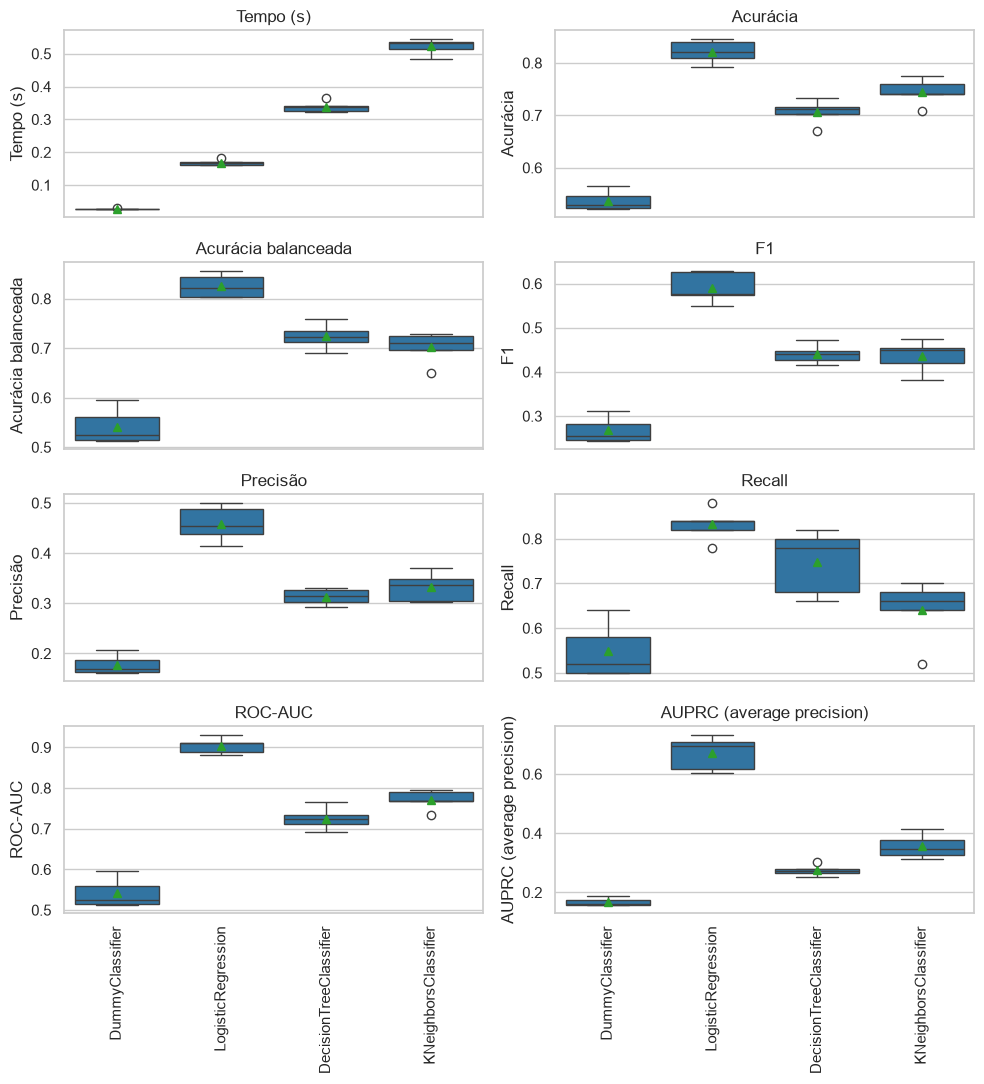

In [5]:
plot_comparar_metricas_modelos(df_resultados, nome_arquivo="comparacao_modelos.png")

A **regressão logística é a melhor em praticamente todas as métricas**: AUPRC de 0,67 (o Dummy fica em 0,17,
perto da taxa de aceite) e ROC-AUC de 0,90. Ela também varia pouco entre os folds e é rápida. A árvore de
decisão sem limite de profundidade se ajusta demais ao treino e generaliza mal (AUPRC de 0,27), e o kNN fica no
meio (0,36). Como também é o modelo mais fácil de explicar, **seguimos com a regressão logística**.

## 5. Otimização de hiperparâmetros

O `GridSearchCV` testa todas as combinações de uma grade de hiperparâmetros, cada uma com a mesma validação
cruzada de 5 folds, e no fim retreina no treino inteiro a combinação com a melhor AUPRC. Os hiperparâmetros são:

| Hiperparâmetro | Valores | Significado |
|---|---|---|
| `clf__C` | 0,1 · 1 · 10 · 100 | Inverso da força da regularização. C pequeno penaliza mais os coeficientes e simplifica o modelo |
| `clf__l1_ratio` | 0 · 0,25 · 0,5 · 0,75 · 1 | Mistura entre regularização L2 (0) e L1 (1), a chamada *elastic net*. A L1 pode zerar coeficientes, funcionando como seleção de variáveis |
| `feature_select__k` | 10 · 15 · 20 · 25 · 30 · todas | Quantas variáveis o `SelectKBest` mantém, pelo teste F da ANOVA |

Usamos o *solver* `saga`, que aceita *elastic net*, com `max_iter=5000` para garantir a convergência.
A partir do scikit-learn 1.8, o tipo de regularização é definido só pelo `l1_ratio` (o parâmetro `penalty` foi
descontinuado).

**Com ou sem undersampling?** O undersampling ajuda o modelo a "enxergar" a classe minoritária, mas tem um efeito
colateral: como ele treina com 50% de aceites, as probabilidades estimadas ficam infladas. Sem undersampling,
a regressão logística tende a produzir **probabilidades calibradas**, e isso permite usar diretamente o ponto de
equilíbrio de 27% como limiar. Como a decisão final será tomada por um limiar escolhido pelo lucro, testamos
as duas versões.

In [6]:
param_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__l1_ratio": [0, 0.25, 0.5, 0.75, 1],
    "feature_select__k": [10, 15, 20, 25, 30, "all"],
}

regressao_logistica = LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE)

grids = {}
for nome, usar_undersampling in [("Com undersampling", True), ("Sem undersampling", False)]:
    grids[nome] = grid_search_classificador(
        regressao_logistica,
        param_grid,
        kf,
        preprocessador,
        undersampling=usar_undersampling,
        metrica_refit="average_precision",
    )
    grids[nome].fit(X_treino, y_treino)

print(f"{len(grids['Com undersampling'].cv_results_['params'])} combinações por versão, 5 folds cada")

120 combinações por versão, 5 folds cada


O atributo `cv_results_` guarda o resultado de cada combinação. As cinco melhores da versão sem undersampling:

In [7]:
colunas_resultado = {
    "params": "hiperparâmetros",
    "mean_test_average_precision": "AUPRC",
    "mean_test_roc_auc": "ROC-AUC",
    "mean_test_precision": "precisão",
    "mean_test_recall": "recall",
}

(
    pd.DataFrame(grids["Sem undersampling"].cv_results_)
    .sort_values("rank_test_average_precision")
    [list(colunas_resultado)]
    .rename(columns=colunas_resultado)
    .head()
    .round(3)
)

,hiperparâmetros,AUPRC,ROC-AUC,precisão,recall
71,"{'clf__C': 10, 'clf__l1_ratio': 0.25, 'feature...",0.696,0.907,0.680,0.492
65,"{'clf__C': 10, 'clf__l1_ratio': 0, 'feature_se...",0.696,0.907,0.683,0.492
77,"{'clf__C': 10, 'clf__l1_ratio': 0.5, 'feature_...",0.694,0.907,0.680,0.500
95,"{'clf__C': 100, 'clf__l1_ratio': 0, 'feature_s...",0.693,0.908,0.677,0.500
119,"{'clf__C': 100, 'clf__l1_ratio': 1, 'feature_s...",0.693,0.908,0.674,0.500


Para comparar as duas versões também pelo lucro, geramos **previsões fora da amostra** (*out-of-fold*) no treino:
com `cross_val_predict`, cada cliente recebe a probabilidade estimada por um modelo que não o viu no treino.
Com elas calculamos o maior lucro que cada versão alcançaria.

In [8]:
probabilidades_oof = {
    nome: cross_val_predict(
        grid.best_estimator_, X_treino, y_treino, cv=kf, method="predict_proba", n_jobs=-1
    )[:, 1]
    for nome, grid in grids.items()
}

comparacao = pd.DataFrame(
    {
        nome: {
            "C": grid.best_params_["clf__C"],
            "l1_ratio": grid.best_params_["clf__l1_ratio"],
            "k (SelectKBest)": grid.best_params_["feature_select__k"],
            "AUPRC (validação cruzada)": f"{grid.best_score_:.3f}",
            "ROC-AUC (validação cruzada)": f"{grid.cv_results_['mean_test_roc_auc'][grid.best_index_]:.3f}",
            "lucro máximo out-of-fold (MU)": f"{curva_de_lucro(y_treino, probabilidades_oof[nome])['lucro'].max():,.0f}",
            "probabilidade média prevista": f"{probabilidades_oof[nome].mean():.1%}",
            "taxa real de aceite no treino": f"{y_treino.mean():.1%}",
        }
        for nome, grid in grids.items()
    }
)
comparacao

,Com undersampling,Sem undersampling
C,10,10
l1_ratio,0.5,0.25
k (SelectKBest),all,all
AUPRC (validação cruzada),0.676,0.696
ROC-AUC (validação cruzada),0.905,0.907
lucro máximo out-of-fold (MU),"1,040","1,112"
probabilidade média prevista,31.9%,15.6%
taxa real de aceite no treino,15.5%,15.5%


A versão **sem undersampling** é melhor nos três critérios avaliados no treino: AUPRC (0,70 contra 0,68),
ROC-AUC e lucro máximo *out-of-fold* (1.112 MU contra 1.040 MU).

A diferença mais importante está nas duas últimas linhas: **sem undersampling, a probabilidade média prevista
(15,6%) é praticamente igual à taxa real de aceite (15,5%)**; com undersampling, ela é o dobro. Nas duas versões,
o melhor resultado usou todas as variáveis (`k = all`): a regularização já reduz o peso das variáveis pouco
úteis, e a seleção pelo `SelectKBest` não trouxe ganho.

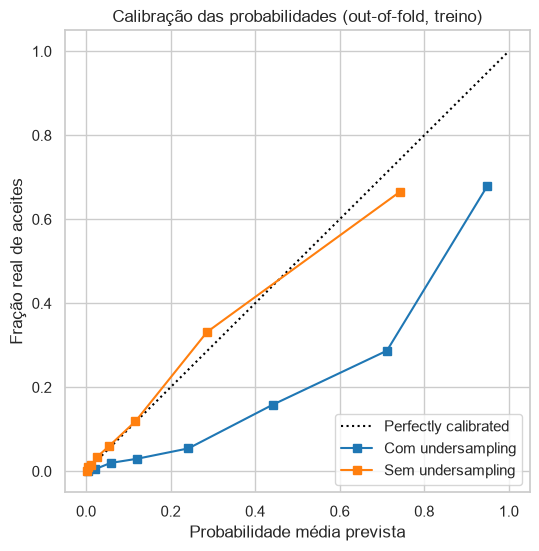

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))

for nome, probabilidades in probabilidades_oof.items():
    CalibrationDisplay.from_predictions(y_treino, probabilidades, n_bins=8, strategy="quantile", name=nome, ax=ax)

ax.set_xlabel("Probabilidade média prevista")
ax.set_ylabel("Fração real de aceites")
ax.set_title("Calibração das probabilidades (out-of-fold, treino)")
plt.show()

A curva de calibração confirma: **sem undersampling, os pontos ficam perto da diagonal** (quando o modelo diz 30%,
cerca de 30% aceitam); **com undersampling, as probabilidades ficam bem acima da realidade**.
Seguimos com a versão sem undersampling.

In [10]:
MODELO_ESCOLHIDO = "Sem undersampling"

modelo = grids[MODELO_ESCOLHIDO].best_estimator_
probabilidade_oof = probabilidades_oof[MODELO_ESCOLHIDO]

modelo

,steps,"[('preprocessor', ...), ('feature_select', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](34,)","['Education','Marital_Status','Income',...,'AcceptedCmpTotal', 'HasAcceptedCmp','NumTotalPurchases']"
n_features_in_,int,34
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('one_hot', ...), ('standard', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


## 6. Curvas ROC e precisão × recall

As curvas usam as **probabilidades** previstas (`method="predict_proba"`), e não as classes 0/1. Com classes,
a curva ROC teria um único ponto de corte e subestimaria a área.

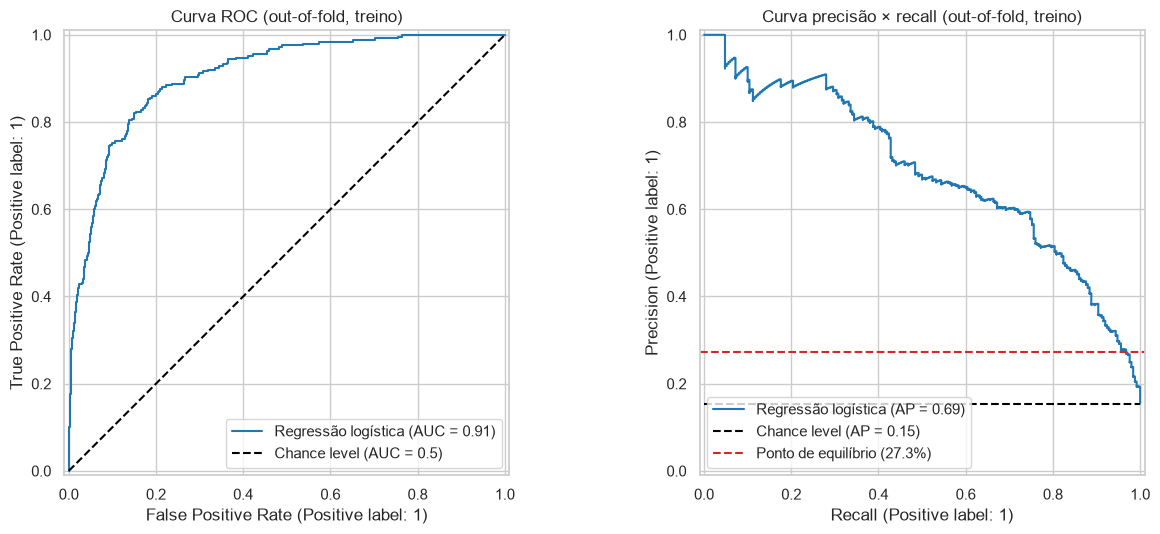

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))

RocCurveDisplay.from_predictions(y_treino, probabilidade_oof, name="Regressão logística", plot_chance_level=True, ax=axs[0])
axs[0].set_title("Curva ROC (out-of-fold, treino)")

PrecisionRecallDisplay.from_predictions(y_treino, probabilidade_oof, name="Regressão logística", plot_chance_level=True, ax=axs[1])
axs[1].axhline(LIMIAR_EQUILIBRIO, color="tab:red", linestyle="--", label=f"Ponto de equilíbrio ({LIMIAR_EQUILIBRIO:.1%})")
axs[1].legend(loc="lower left")
axs[1].set_title("Curva precisão × recall (out-of-fold, treino)")

plt.tight_layout()
salvar_figura(fig, "curvas_roc_pr.png")
plt.show()

- **ROC-AUC de 0,91:** se sortearmos um cliente que aceitou e um que não aceitou, em 91% das vezes o modelo dá
  probabilidade maior a quem aceitou.
- **Precisão × recall:** a curva mostra o custo de ampliar a campanha. Entre os clientes de maior probabilidade, a
  precisão passa de 80%; para capturar mais aceites (recall maior), é preciso incluir clientes menos propensos, e a
  precisão cai. A linha vermelha marca 27,3%: enquanto a precisão acumulada está acima dela, a campanha como um
  todo dá lucro. O lucro máximo, porém, vem bem antes, no ponto em que o próximo cliente da lista tem menos de
  27% de chance de aceitar. É o que a seção 7 calcula.

## 7. Análise de lucro por limiar

Ordenando os clientes da maior para a menor probabilidade e contatando-os nessa ordem, calculamos o lucro para
cada quantidade de contatos (função `curva_de_lucro` em [`src/modelos.py`](src/modelos.py)).

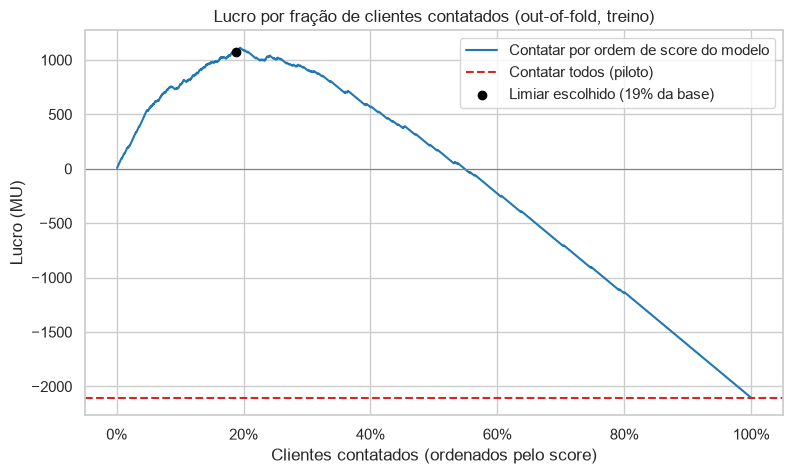

,limiar,contatados,pct_contatados,aceites,precisao,recall,lucro
limiar 27% (equilíbrio),27.4%,305,18.9%,181,59.3%,72.4%,"1,076"
limiar de lucro máximo,25.9%,315,19.5%,187,59.4%,74.8%,"1,112"
limiar 50% (padrão),50.1%,182,11.2%,123,67.6%,49.2%,807


In [12]:
curva_treino = curva_de_lucro(y_treino, probabilidade_oof)
lucro_todos_treino = lucro_campanha(y_treino, np.ones(len(y_treino), dtype=bool))

ponto_equilibrio = curva_treino[curva_treino["limiar"] >= LIMIAR_EQUILIBRIO].iloc[-1]
ponto_maximo = curva_treino.loc[curva_treino["lucro"].idxmax()]
ponto_50 = curva_treino[curva_treino["limiar"] >= 0.5].iloc[-1]

plot_curva_de_lucro(
    curva_treino,
    lucro_todos_treino,
    ponto_escolhido=ponto_equilibrio,
    titulo="Lucro por fração de clientes contatados (out-of-fold, treino)",
)

pd.DataFrame(
    {
        "limiar 27% (equilíbrio)": ponto_equilibrio,
        "limiar de lucro máximo": ponto_maximo,
        "limiar 50% (padrão)": ponto_50,
    }
).T[["limiar", "contatados", "pct_contatados", "aceites", "precisao", "recall", "lucro"]].style.format(
    {"limiar": "{:.1%}", "contatados": "{:.0f}", "pct_contatados": "{:.1%}", "aceites": "{:.0f}",
     "precisao": "{:.1%}", "recall": "{:.1%}", "lucro": "{:,.0f}"}
)

- **O limiar de 27% (ponto de equilíbrio) fica muito perto do ótimo empírico** (26%). Ele contata 19% dos clientes,
  captura 72% dos aceites com precisão de 59% e gera 97% do lucro máximo (1.076 contra 1.112 MU). Isso acontece
  porque as probabilidades estão calibradas: contatar um cliente com probabilidade *p* rende, em média,
  11*p* − 3 MU, valor positivo quando *p* > 3/11.
- **O limiar padrão de 50% deixa dinheiro na mesa:** contata menos gente, perde metade dos aceites e lucra 807 MU.
- Contatar todos os clientes do treino daria prejuízo de 2.104 MU.

**Escolhemos o limiar de 27%.** Ele tem justificativa econômica direta, não depende de um ajuste fino a uma curva
com ruído e acompanha mudanças de preço: se o custo ou a receita mudarem, basta recalcular custo ÷ receita.

## 8. Avaliação final no conjunto de teste

Agora, e só agora, usamos o conjunto de teste: 20% dos clientes que não participaram de nenhuma escolha.

ROC-AUC no teste: 0.920
AUPRC no teste:   0.720


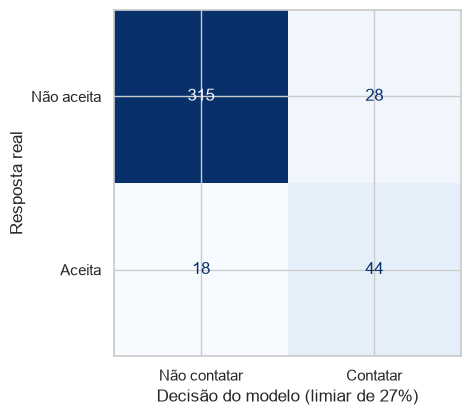

In [13]:
probabilidade_teste = modelo.predict_proba(X_teste)[:, 1]
contatar = probabilidade_teste >= LIMIAR_EQUILIBRIO

print(f"ROC-AUC no teste: {roc_auc_score(y_teste, probabilidade_teste):.3f}")
print(f"AUPRC no teste:   {average_precision_score(y_teste, probabilidade_teste):.3f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, contatar, display_labels=["Não aceita", "Aceita"], cmap="Blues", colorbar=False, ax=ax
)
ax.set_xticklabels(["Não contatar", "Contatar"])
ax.set_xlabel("Decisão do modelo (limiar de 27%)")
ax.set_ylabel("Resposta real")
plt.show()

In [14]:
clusters_teste = pd.read_parquet(DADOS_CLUSTERIZADOS).loc[X_teste.index, "Cluster"]
taxa_aceite_teste = y_teste.mean()

estrategias = {
    "Contatar todos (como no piloto)": np.ones(len(y_teste), dtype=bool),
    "Contatar só o cluster 2 (alto valor)": (clusters_teste == 2).to_numpy(),
    "Modelo de propensão (limiar de 27%)": contatar,
}

tabela_estrategias = pd.DataFrame(
    {
        nome: {
            "contatados": selecao.sum(),
            "aceites": y_teste[selecao].sum(),
            "precisão": y_teste[selecao].mean(),
            "recall": y_teste[selecao].sum() / y_teste.sum(),
            "lucro (MU)": lucro_campanha(y_teste, selecao),
        }
        for nome, selecao in estrategias.items()
    }
).T

# referência: sortear a mesma quantidade de clientes que o modelo contata
n_modelo = contatar.sum()
tabela_estrategias.loc["Sorteio aleatório (mesma quantidade do modelo)"] = {
    "contatados": n_modelo,
    "aceites": n_modelo * taxa_aceite_teste,
    "precisão": taxa_aceite_teste,
    "recall": n_modelo / len(y_teste),
    "lucro (MU)": n_modelo * (RECEITA_ACEITE * taxa_aceite_teste - CUSTO_CONTATO),
}

tabela_estrategias.style.format(
    {"contatados": "{:.0f}", "aceites": "{:.0f}", "precisão": "{:.1%}", "recall": "{:.1%}", "lucro (MU)": "{:,.0f}"}
)

,contatados,aceites,precisão,recall,lucro (MU)
Contatar todos (como no piloto),405,62,15.3%,100.0%,-533
Contatar só o cluster 2 (alto valor),122,35,28.7%,56.5%,19
Modelo de propensão (limiar de 27%),72,44,61.1%,71.0%,268
Sorteio aleatório (mesma quantidade do modelo),72,11,15.3%,17.8%,-95


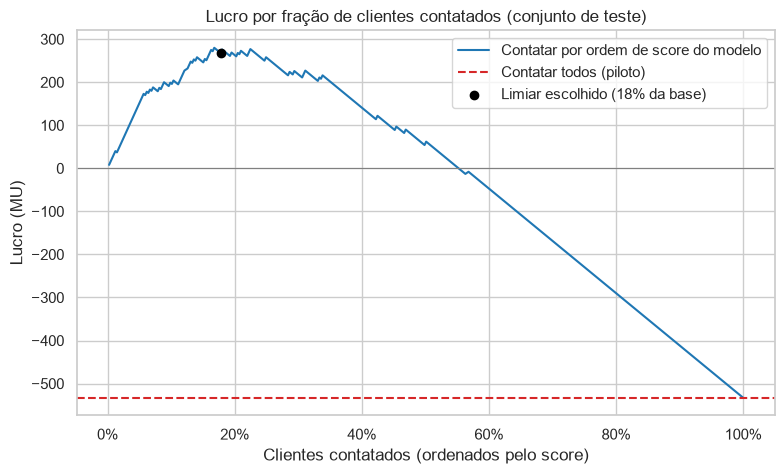

In [15]:
curva_teste = curva_de_lucro(y_teste, probabilidade_teste)
ponto_teste = curva_teste[curva_teste["limiar"] >= LIMIAR_EQUILIBRIO].iloc[-1]

plot_curva_de_lucro(
    curva_teste,
    lucro_campanha(y_teste, estrategias["Contatar todos (como no piloto)"]),
    ponto_escolhido=ponto_teste,
    titulo="Lucro por fração de clientes contatados (conjunto de teste)",
    nome_arquivo="curva_de_lucro.png",
)

**Quanto isso representa numa campanha do tamanho do piloto?** O teste tem poucos clientes, então estimamos o lucro
por cliente da base e a incerteza com *bootstrap*: sorteamos 2.000 amostras do teste, com reposição, e
recalculamos o lucro em cada uma.

In [16]:
rng = np.random.default_rng(RANDOM_STATE)
y_teste_array = y_teste.to_numpy()

lucro_por_cliente = []
for _ in range(2000):
    indices = rng.integers(0, len(y_teste_array), len(y_teste_array))
    lucro_por_cliente.append(lucro_campanha(y_teste_array[indices], contatar[indices]) / len(indices))

TAMANHO_PILOTO = 2240
estimativa = lucro_campanha(y_teste, contatar) / len(y_teste) * TAMANHO_PILOTO
inferior, superior = np.percentile(lucro_por_cliente, [5, 95]) * TAMANHO_PILOTO

print(f"Lucro estimado para {TAMANHO_PILOTO:,} clientes: {estimativa:,.0f} MU (intervalo de 90%: {inferior:,.0f} a {superior:,.0f} MU)")
print(f"Contatos: {contatar.mean():.0%} da base, cerca de {contatar.mean() * TAMANHO_PILOTO:,.0f} ligações")
print(f"Lucro do piloto, que contatou todos: {RECEITA_ACEITE * 334 - CUSTO_CONTATO * TAMANHO_PILOTO:,} MU")

Lucro estimado para 2,240 clientes: 1,482 MU (intervalo de 90%: 1,001 a 1,997 MU)
Contatos: 18% da base, cerca de 398 ligações
Lucro do piloto, que contatou todos: -3,046 MU


**Resultado nos 405 clientes do teste, que o modelo nunca viu:**

- **ROC-AUC de 0,92 e AUPRC de 0,72**, em linha com a validação cruzada (0,91 e 0,70): o modelo não está
  sobreajustado.
- O modelo contata **72 clientes (18%)** e encontra **44 dos 62 que aceitariam (71%)**, com **precisão de 61%**,
  quatro vezes a taxa de aceite da base.
- **Lucro de +268 MU, contra −533 MU se todos fossem contatados.** Sortear a mesma quantidade de clientes daria
  −95 MU, e contatar só o cluster de alto valor, +19 MU.
- A curva de lucro do teste tem o pico perto dos 18% de clientes contatados, justamente onde o limiar caiu.
- **Para uma base do tamanho do piloto (2.240 clientes), o lucro estimado é de cerca de 1.480 MU** (intervalo
  de 90%: 1.000 a 2.000 MU), com cerca de 400 ligações em vez de 2.240. **O piloto teve prejuízo de 3.046 MU.**

## 9. Interpretação do modelo

Na regressão logística, cada coeficiente indica como a variável altera a chance de aceite, mantidas as demais
constantes. Coeficientes positivos aumentam a chance; negativos diminuem. Para as variáveis binárias, $e^{\text{coef}}$
é a **razão de chances** (*odds ratio*): quanto a chance de aceite é multiplicada quando a variável vale 1.
As variáveis contínuas foram padronizadas, então seus coeficientes valem para uma variação de cerca de
um desvio padrão.

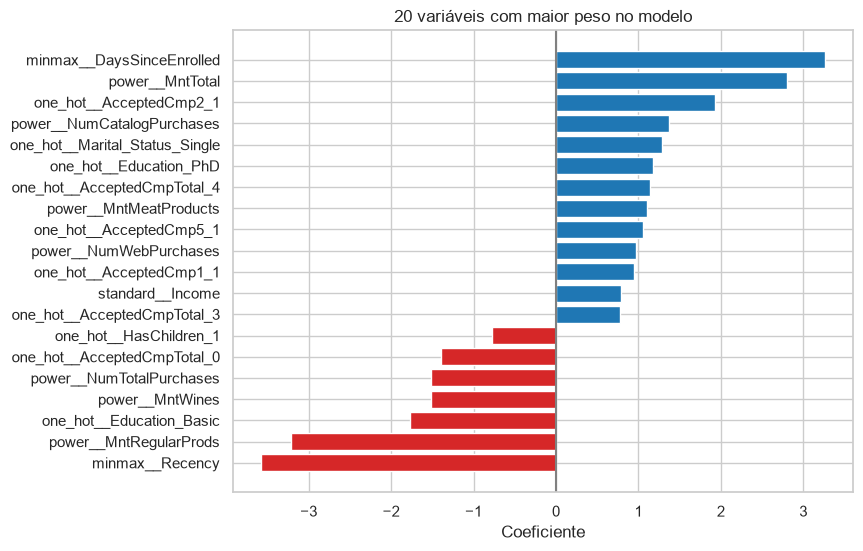

In [17]:
coeficientes = dataframe_coeficientes(
    modelo["clf"].coef_[0],
    modelo[:-1].get_feature_names_out(),
)

maiores = coeficientes.loc[coeficientes["coeficiente"].abs().sort_values(ascending=False).index[:20]].sort_values("coeficiente")

plot_coeficientes(maiores, titulo="20 variáveis com maior peso no modelo", nome_arquivo="coeficientes.png")

In [18]:
binarias = coeficientes[coeficientes.index.str.startswith("one_hot")].copy()
binarias["odds_ratio"] = np.exp(binarias["coeficiente"])
binarias.sort_values("odds_ratio", ascending=False).head(8).round(2)

,coeficiente,odds_ratio
one_hot__AcceptedCmp2_1,1.93,6.92
one_hot__Marital_Status_Single,1.28,3.61
one_hot__Education_PhD,1.18,3.26
one_hot__AcceptedCmpTotal_4,1.15,3.14
one_hot__AcceptedCmp5_1,1.06,2.87
one_hot__AcceptedCmp1_1,0.94,2.57
one_hot__AcceptedCmpTotal_3,0.77,2.17
one_hot__AcceptedCmp3_1,0.73,2.07


**Principais fatores** (coeficientes do modelo treinado no conjunto de treino):

- **Tempo de cadastro (+) e recência (−) são as variáveis de maior peso.** Clientes há mais tempo na base e que
  compraram recentemente têm muito mais chance de aceitar: é o perfil do cliente fiel e ativo.
- **Histórico de campanhas:** ter aceitado as campanhas 1, 2 ou 5 multiplica a chance de aceite (razão de chances
  entre 2,6 e 6,9), e nunca ter aceitado uma campanha (`AcceptedCmpTotal_0`) reduz. A razão de chances da
  campanha 2 deve ser lida com cuidado, porque só 1,4% dos clientes aceitaram essa campanha.
- **Perfil:** ser solteiro (3,6 vezes a chance) e ter doutorado (3,3 vezes) aumentam a propensão; escolaridade
  básica e ter filhos diminuem. O modelo confirma o que a análise exploratória já mostrava.
- **Canal:** com o total de compras fixo, mais compras por catálogo e pelo site aumentam a chance. O coeficiente
  negativo de `NumTotalPurchases`, somado aos positivos de catálogo e site, indica que compras em loja física
  pesam contra.
- **Cuidado com variáveis redundantes:** `MntTotal` (+), `MntRegularProds` (−) e `MntWines` (−) são fortemente
  correlacionadas (o total é a soma das outras) e seus coeficientes se compensam. Não devem ser lidos
  isoladamente; juntos, indicam que gasto alto aumenta a chance de aceite.

**Quem o modelo escolheria?** Cruzando os clientes selecionados no teste com a segmentação da Parte 2:

In [19]:
selecionados = pd.DataFrame({"Cluster": clusters_teste, "contatar": contatar, "aceitou": y_teste})

pd.DataFrame(
    {
        "clientes no teste": selecionados.groupby("Cluster").size(),
        "contatados pelo modelo": selecionados.groupby("Cluster")["contatar"].sum(),
        "% do cluster contatado": selecionados.groupby("Cluster")["contatar"].mean(),
        "aceites capturados": selecionados[selecionados["contatar"]].groupby("Cluster")["aceitou"].sum(),
        "aceites no cluster": selecionados.groupby("Cluster")["aceitou"].sum(),
    }
).style.format({"% do cluster contatado": "{:.0%}"})

,clientes no teste,contatados pelo modelo,% do cluster contatado,aceites capturados,aceites no cluster
Cluster,,,,,
0,148,10,7%,7,12
1,135,18,13%,6,15
2,122,44,36%,31,35


- O modelo **concentra os contatos no cluster 2** (alto valor): 44 dos 72 contatos, que capturam 31 dos 35 aceites
  do cluster.
- Mas também **encontra clientes propensos nos outros grupos**: os 28 contatos nos clusters 0 e 1 capturam
  13 aceites, 30% de todos os aceites capturados. Uma regra por cluster perderia esses clientes e, ao mesmo tempo,
  ligaria para 78 clientes do cluster 2 que o modelo descarta.
- É por isso que o modelo lucra muito mais que a estratégia "contatar só o cluster 2".

## 10. Modelo final

Para uso na próxima campanha, retreinamos o pipeline escolhido (mesmos hiperparâmetros) com **todos os
2.023 clientes** e salvamos o modelo junto com o limiar de decisão.

In [20]:
modelo_final = clone(modelo).fit(X, y)

artefato = {
    "modelo": modelo_final,
    "limiar": LIMIAR_EQUILIBRIO,
    "colunas": X.columns.tolist(),
    "versao_scikit_learn": sklearn.__version__,
}

MODELO_FINAL.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(artefato, MODELO_FINAL)

print(f"Modelo salvo em modelos/{MODELO_FINAL.name}")

Modelo salvo em modelos/modelo_propensao.joblib


Exemplo de uso: carregar o modelo, calcular a probabilidade de cada cliente e gerar a lista de contatos.

In [21]:
carregado = joblib.load(MODELO_FINAL)

clientes = X.sample(5, random_state=RANDOM_STATE)
probabilidades = carregado["modelo"].predict_proba(clientes[carregado["colunas"]])[:, 1]

pd.DataFrame(
    {"probabilidade_aceite": probabilidades, "contatar": probabilidades >= carregado["limiar"]},
    index=clientes.index,
).style.format({"probabilidade_aceite": "{:.1%}"})

,probabilidade_aceite,contatar
ID,,
6969,0.9%,False
9503,42.2%,True
7573,93.4%,True
6941,6.4%,False
1177,3.9%,False


## 11. Conclusões

**Resposta aos três entregáveis do case:**

1. **Quem aceita a oferta** ([Parte 1](01_eda_e_tratamento.ipynb)): clientes que já aceitaram campanhas, com renda
   e gasto altos, sem filhos, solteiros, com maior escolaridade, há mais tempo na base e com compra recente.
2. **Segmentação** ([Parte 2](02_segmentacao_clientes.ipynb)): três clusters, "orçamento apertado" (40% da base),
   "famílias estabelecidas" (34%) e "alto valor" (26%), com taxas de aceite de 10%, 12% e 29%.
3. **Modelo para maximizar o lucro** (este notebook): regressão logística com *elastic net*, sem undersampling,
   com probabilidades calibradas e limiar econômico de 27%. No teste, ROC-AUC de 0,92, precisão de 61% e recall de
   71%, com **lucro de +268 MU contra −533 MU** de contatar todos. Para 2.240 clientes, a estimativa é de
   **+1.480 MU, contra −3.046 MU do piloto**, com 82% menos ligações.

**Recomendação:** usar o modelo para escolher quem recebe a ligação (cerca de 18% da base) e adaptar a abordagem
ao cluster de cada cliente (catálogo e ofertas premium para o alto valor, descontos para as famílias
estabelecidas, canais digitais para os demais).

**Limitações:**

- **Amostra pequena:** o teste tem 62 aceites. O intervalo do *bootstrap* (1.000 a 2.000 MU) mostra a incerteza
  da estimativa.
- **Premissa de estabilidade:** o modelo supõe que a próxima campanha se comporta como o piloto (mesmo tipo de
  oferta e canal, custo e receita fixos por cliente).
- **Momento da coleta:** não sabemos se variáveis como `Recency` foram medidas antes ou depois da campanha piloto.
  Se foram medidas depois, parte do sinal pode vir da própria compra do gadget. Vale confirmar com a área de dados.
- **Variáveis redundantes** dificultam a leitura individual de alguns coeficientes.

**Próximos passos:**

- Validar com um **teste A/B** na próxima campanha, mantendo um grupo de controle escolhido aleatoriamente;
- Testar modelos de *gradient boosting* e compará-los **pelo lucro**, não só pela AUPRC;
- Reduzir variáveis redundantes para facilitar a interpretação;
- Incorporar custo e receita por cliente, se a empresa tiver esses dados.